In [1]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt

In [8]:
d = 11 #last 2 digit of id
categories = ['C', 'C++', 'Java', 'Python']

In [9]:
o_c = 20 + d
o_cpp = 25 + (d % 10)
o_java = 30 + (d % 7)
o_python = 35 + (d % 5)


In [10]:
observed = np.array([o_c, o_cpp, o_java, o_python])

In [11]:
print("Calculated Observed Frequencies (O):")
for cat, obs in zip(categories, observed):
    print(f"  {cat}: {obs}")

Calculated Observed Frequencies (O):
  C: 31
  C++: 26
  Java: 34
  Python: 36


In [12]:
total = np.sum(observed)
expected = np.full_like(observed, total / len(observed), dtype=np.float64)

print(f"\nTotal sample size (N): {total}")
print(f"Expected Frequency (E) for each category: {total / len(observed):.2f}")


Total sample size (N): 127
Expected Frequency (E) for each category: 31.75


In [13]:
chi_square_stat = np.sum(((observed - expected) ** 2) / expected)
# SciPy built-in function
chi2_scipy, p_value = stats.chisquare(f_obs=observed, f_exp=expected)

In [14]:
df = len(observed) - 1

In [15]:
alpha = 0.05  # 5% Significance level
critical_value = stats.chi2.ppf(1 - alpha, df)

In [16]:
print("\n--- Chi-Square Test Results ---")
print(f"Chi-square statistic: {chi_square_stat:.4f}")
print(f"Degrees of freedom: {df}")
print(f"Critical value (0.05 significance level): {critical_value:.4f}")
print(f"P-value: {p_value:.4f}")


--- Chi-Square Test Results ---
Chi-square statistic: 1.7874
Degrees of freedom: 3
Critical value (0.05 significance level): 7.8147
P-value: 0.6177


In [17]:
print("\n--- Decision & Conclusion ---")
if chi_square_stat > critical_value:
    print("Decision: Reject the null hypothesis (H0).")
    print("Conclusion: Students do not have an equal preference for the four programming languages.")
else:
    print("Decision: Fail to reject the null hypothesis (H0).")
    print("Conclusion: There is no significant difference in student preferences; student preferences for C, C++, Java, and Python are equally distributed.")


--- Decision & Conclusion ---
Decision: Fail to reject the null hypothesis (H0).
Conclusion: There is no significant difference in student preferences; student preferences for C, C++, Java, and Python are equally distributed.


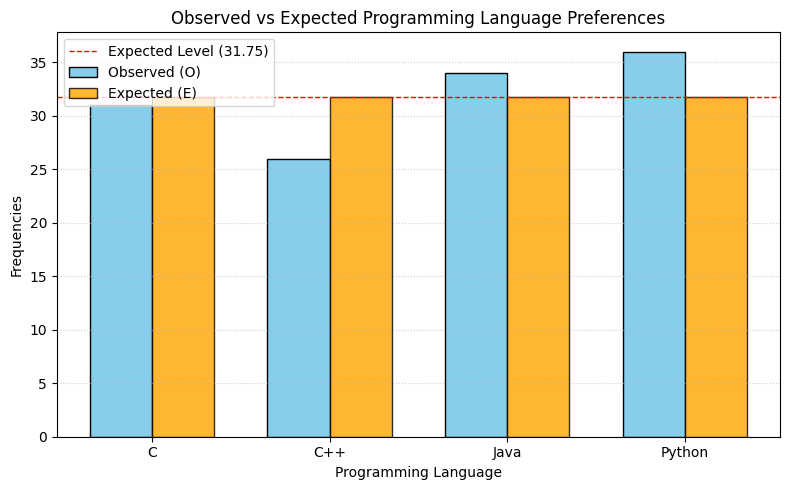

In [18]:
x = np.arange(len(categories))
width = 0.35

plt.figure(figsize=(8, 5))
plt.bar(x - width/2, observed, width=width, label='Observed (O)', color='skyblue', edgecolor='black')
plt.bar(x + width/2, expected, width=width, label='Expected (E)', color='orange', edgecolor='black', alpha=0.8)

plt.xlabel('Programming Language')
plt.ylabel('Frequencies')
plt.title('Observed vs Expected Programming Language Preferences')
plt.xticks(x, categories)
plt.axhline(expected[0], color='red', linestyle='--', linewidth=1, label=f'Expected Level ({expected[0]:.2f})')
plt.legend()
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()